# 臺灣 UVI 研究｜VIIRS 夜間燈光 2023/11 × 368 鄉鎮分析

**Google Colab 可直接執行（繁體中文教學版）**

目標：從先前的 VIIRS 2023 年 11 月 `avg_rade9h` 和 `cf_cvg` GeoTIFF（或原始 EOG `.tgz`）出發，產出 **368 鄉鎮的夜間燈光統計、品質檢核、與既有 UVI 活動／消費構面比較、地圖、圖表、CSV**。

### 先了解三個重要限制
1. 此處的 NTL 指 **夜間衛星輻射亮度**，不是「夜間人流」，也不是已證實的城市活力總分。
2. `cf_cvg=0` 代表沒有無雲有效觀測。**不能將它當作零亮度**。本 Notebook 主要使用 `cf_cvg ≥ 1`；另以 `≥ 3` 做敏感度檢查（3 是研究者自訂門檻，非官方標準）。
3. 已知 UVI 的 S1–S6 是 **候選診斷分數**；本程式只做與夜光的比較，**不自動把 NTL 加到 UVI 權重**。

### 檔案位置（沿用舊專案）

```
我的雲端硬碟 / UVI_NTL /
  raw/          ← 原始 SVDNB...avg_rade9h.tif、...cf_cvg.tif，或 .tgz
  output/       ← 舊版臺灣裁切 TIFF；本次也會輸出所有 CSV/PNG/ZIP
  boundaries/   ← 行政區界線 ZIP；沒有時會嘗試從內政部官方網站下載
```

**執行方式：**依序點每個程式區塊左邊的 ▶，出現綠色勾勾再往下。第一遍不要使用「全部執行」，方便看檔案檢查訊息。執行失敗請直接把「出錯的步驟標題 + 完整紅字」傳回 ChatGPT。

資料來源：EOG VIIRS Monthly Cloud-free DNB Composite (`vcmcfg`，2023/11)；內政部國土測繪中心鄉鎮界線；研究團隊 UVI Stage 1 v0.1 已核實候選分數。頁面：
- https://eogdata.mines.edu/products/vnl/
- https://maps.nlsc.gov.tw/pro/download.jsp
- https://data.gov.tw/dataset/7441

### 本版新增（依教授建議）
- 2023年11月夜光平均值／中位數／P90，分別與F、C、S1計算Spearman相關。
- 各對變數**控制2023年11月登記人口後的偏Spearman相關**（先將三變數取秩，再回歸剔除人口秩的線性影響）。
- 匯出NTL與候選構面**相對排名差異最大的鄉鎮名單**，供後續核查，不直接認定為資料錯誤。
- 會區分數值不足、影像範圍不全及像元少的行政區；無法把缺值當作0。
- 注意：本次不計算LISA或執行完整P0變數稽核，待你把NTL結果交回後再進行。

**實際輸入仍須你的VIIRS兩張GeoTIFF或官方原始封裝檔。Notebook內建的是368鄉鎮UVI參考表，不含真正NTL亮度。**


## 步驟 1｜安裝所需套件

Colab 每次重新啟動運算環境，都可能需要再執行一次。安裝訊息有 warning 不一定代表失敗；如顯示 `ERROR` 請停止。

In [1]:
%pip -q install "rasterio>=1.3" "geopandas>=0.14" "pyogrio>=0.8" "shapely>=2.0" "scipy>=1.10" "openpyxl>=3.1"

## 步驟 2｜連結 Google Drive、建立資料夾

執行後會跳出 Google 授權，選擇存放 `UVI_NTL` 的 Google 帳號並允許掛載。你之前的目錄是 `MyDrive/UVI_NTL`。

如果 Notebook 顯示「找不到任何 TIFF」，**不是程式失敗**：很可能是檔案沒在此帳號，請依步驟 3 的提示上傳。

In [2]:
from pathlib import Path
from google.colab import drive
import os, json, sys, math, re, zipfile, tarfile, shutil, hashlib, io, warnings
import numpy as np
import pandas as pd
import rasterio
import geopandas as gpd
from rasterio.windows import from_bounds, Window
from rasterio.features import geometry_mask
from rasterio.warp import transform_bounds
from rasterio.transform import array_bounds
from rasterio.crs import CRS
from shapely.geometry import box
from scipy.stats import spearmanr
import matplotlib.pyplot as plt

drive.mount('/content/drive')
BASE = Path('/content/drive/MyDrive/UVI_NTL')
RAW, OUT, BOUND = BASE/'raw', BASE/'output', BASE/'boundaries'
for x in (RAW,OUT,BOUND): x.mkdir(parents=True, exist_ok=True)
print('Google Drive 路徑:', BASE)
print('raw:',len(list(RAW.iterdir())),'項； output:',len(list(OUT.iterdir())),'項； boundaries:',len(list(BOUND.iterdir())),'項')

# 舊版裁切範圍：118–122.5°E、21.5–26.5°N，只適合一般臺灣附近島嶼；
# 為更完整涵蓋外島/海外行政區，若從原始大圖重新裁切，改採寬範圍。仍會記錄資料覆蓋比例。
NEW_CLIP_BBOX_WGS84 = (114.0, 10.0, 125.0, 27.0)  # left,bottom,right,top
MIN_CF_MAIN = 1
MIN_CF_SENSITIVITY = 3
ALL_TOUCHED = False  # 像元中心落在鄉鎮才算；小島像元數可能少，需品質註記
print('設定完成。')

Mounted at /content/drive
Google Drive 路徑: /content/drive/MyDrive/UVI_NTL
raw: 2 項； output: 2 項； boundaries: 0 項
設定完成。


## 步驟 3｜找出夜光原始資料（`avg_rade9h` + `cf_cvg`）

這步會依序尋找：
- `output/Taiwan_NTL_2023_11_avg_rade9h.tif` + `...cf_cvg.tif`（你之前曾有的裁切結果）
- `raw/SVDNB_npp_20231101-20231130_75N060E_vcmcfg_v10_c202312080900.avg_rade9h.tif` + `...cf_cvg.tif`
- `raw/*.tgz` 中的原始 TIFF（會在 Colab 暫存區解壓）。

找不到時會列出資料夾清單，**然後停止並說明如何補檔**。舊成果可能在另一個 Google 帳號，或根本沒有同步進 Drive。直接把現有的兩個 TIFF 移進 `UVI_NTL/output`，重新執行本格即可。

如果一定要重新下載 EOG 原始 `.tgz`，請從官方頁面依 **2023 → November → VCMCFG → 75N060E** 找到對應檔，下載後上傳到 `UVI_NTL/raw`；來源檔可能很大，先用 Drive 上傳，不要在 Colab 直接用瀏覽器上傳數 GB。

In [3]:
# 亦可改成兩個自行指定的完整路徑；不指定則自動尋找。
OVERRIDE_RADIANCE = ''
OVERRIDE_COVERAGE = ''

def locate_pair():
    if OVERRIDE_RADIANCE and OVERRIDE_COVERAGE:
        return Path(OVERRIDE_RADIANCE),Path(OVERRIDE_COVERAGE),'manual'
    known = [
       ('Taiwan_NTL_2023_11_avg_rade9h.tif','Taiwan_NTL_2023_11_cf_cvg.tif'),
       ('NTL_202311_Taiwan_avg_rade9h.tif','NTL_202311_Taiwan_cf_cvg.tif'),
    ]
    roots=[OUT, RAW, BASE, Path('/content')]
    for r in roots:
        for a,b in known:
            if (r/a).is_file() and (r/b).is_file():return r/a,r/b,'clipped'
    for root in roots:
        for a in sorted(root.glob('*.avg_rade9h.tif')):
            if '202311' not in a.name:continue
            b=Path(str(a).replace('.avg_rade9h.tif','.cf_cvg.tif'))
            if b.exists():return a,b,'raw'
    # .tgz 原始資料壓縮包；只抽需要的兩個 TIFF
    archives=list(RAW.glob('*202311*.tgz'))+list(RAW.glob('*202311*.tar.gz'))
    if archives:
        arc=archives[0]
        print('找到原始壓縮包：',arc.name,'；只解壓所需的兩個 TIFF...')
        temp=Path('/content/UVI_NTL_EXTRACT');temp.mkdir(exist_ok=True)
        res={}
        with tarfile.open(arc,'r:gz') as tar:
            for t in tar:
                if not t.isfile(): continue
                name=Path(t.name).name
                if name.endswith('.avg_rade9h.tif') or name.endswith('.cf_cvg.tif'):
                    if '202311' not in name:continue
                    dest=temp/name
                    if not dest.exists():
                        f=tar.extractfile(t)
                        if f is None:continue
                        with f,open(dest,'wb') as w: shutil.copyfileobj(f,w,8*1024*1024)
                    res['rad' if name.endswith('.avg_rade9h.tif') else 'cvg']=dest
        if {'rad','cvg'} <=res.keys():return res['rad'],res['cvg'],'raw'
    print('\n目前資料夾內容：')
    for root in [RAW,OUT,BOUND]:
        print('\n',root)
        for f in list(root.iterdir())[:20]: print('  ',f.name)
    raise FileNotFoundError('找不到同月份的 avg_rade9h.tif 與 cf_cvg.tif。請將兩個檔案放到 UVI_NTL/raw 或 output，重新跑本步。')

RAD_FILE, CF_FILE, INPUT_KIND = locate_pair()
assert RAD_FILE.exists() and CF_FILE.exists()
print('亮度檔：',RAD_FILE, '大小(MB):',round(RAD_FILE.stat().st_size/1e6,2))
print('觀測檔：',CF_FILE, '大小(MB):',round(CF_FILE.stat().st_size/1e6,2))
print('資料型態：', INPUT_KIND)

亮度檔： /content/drive/MyDrive/UVI_NTL/output/Taiwan_NTL_2023_11_avg_rade9h.tif 大小(MB): 3.27
觀測檔： /content/drive/MyDrive/UVI_NTL/output/Taiwan_NTL_2023_11_cf_cvg.tif 大小(MB): 0.39
資料型態： clipped


## 步驟 4｜裁切臺灣研究範圍、檢查座標與影像對齊

- 如果已找到之前的臺灣裁切檔，沿用它（不覆蓋）。
- 若找到原始 EOG 全球／區域大圖，就以 **114–125°E / 10–27°N** 重新裁切，儘量包含外島；這比舊版 118–122.5°E 的裁切範圍寬。所有區域會另做覆蓋率檢查。
- 保留原始像元值與解析度、不做雙線性插值。經緯度 CRS 會記錄，兩個 TIFF 必須同網格。

In [4]:
def clip_window_only(src_path, dest_path, bb_wgs84):
    with rasterio.open(src_path) as ds:
        if ds.crs is None:raise ValueError(f'{src_path.name} 缺少 CRS，不能直接假設是 WGS84。')
        bb=transform_bounds('EPSG:4326',ds.crs,*bb_wgs84,densify_pts=31)
        w=from_bounds(*bb,transform=ds.transform)
        w=w.round_offsets().round_lengths().intersection(Window(0,0,ds.width,ds.height))
        if w.width<1 or w.height<1:raise ValueError('指定的臺灣範圍不在原始影像內。')
        profile=ds.profile.copy()
        profile.update(height=int(w.height),width=int(w.width),transform=ds.window_transform(w),compress='DEFLATE',tiled=True,blockxsize=256,blockysize=256,BIGTIFF='IF_SAFER')
        dest_path.parent.mkdir(parents=True,exist_ok=True)
        with rasterio.open(dest_path,'w',**profile) as dst:
            for _,win in dst.block_windows(1):
                src_win=Window(w.col_off+win.col_off,w.row_off+win.row_off,win.width,win.height)
                dst.write(ds.read(1,window=src_win),1,window=win)
    return dest_path

if INPUT_KIND == 'raw':
    # 避免覆蓋之前同名、裁切較小的結果，保留兩套供追溯
    RAD_CLIP=OUT/'Taiwan_NTL_2023_11_FULL_avg_rade9h.tif'
    CF_CLIP=OUT/'Taiwan_NTL_2023_11_FULL_cf_cvg.tif'
    if not RAD_CLIP.exists():clip_window_only(RAD_FILE,RAD_CLIP,NEW_CLIP_BBOX_WGS84)
    if not CF_CLIP.exists():clip_window_only(CF_FILE,CF_CLIP,NEW_CLIP_BBOX_WGS84)
else:
    RAD_CLIP,CF_CLIP=RAD_FILE,CF_FILE

with rasterio.open(RAD_CLIP) as r, rasterio.open(CF_CLIP) as c:
    print('亮度：',r.width,'x',r.height,'CRS:',r.crs,'解析度:',r.res,'bounds:',r.bounds)
    print('覆蓋：',c.width,'x',c.height,'CRS:',c.crs,'解析度:',c.res,'bounds:',c.bounds)
    aligned=(r.crs==c.crs and r.width==c.width and r.height==c.height and np.allclose(tuple(r.transform),tuple(c.transform),atol=1e-9))
    if not aligned:
        raise ValueError('亮度與無雲觀測圖不是相同網格，請確認同一來源與裁切範圍；本Notebook不會用插值偷偷對齊。')
    assert r.count==1 and c.count==1, '預期每一份 TIFF 各有一個 band。'
    print('PASS：兩張影像的 CRS、像元格網、尺寸一致')

亮度： 1080 x 1200 CRS: EPSG:4326 解析度: (0.0041666667, 0.0041666667) bounds: BoundingBox(left=117.99791713065, bottom=21.502082905349997, right=122.49791716665, top=26.502082945349997)
覆蓋： 1080 x 1200 CRS: EPSG:4326 解析度: (0.0041666667, 0.0041666667) bounds: BoundingBox(left=117.99791713065, bottom=21.502082905349997, right=122.49791716665, top=26.502082945349997)
PASS：兩張影像的 CRS、像元格網、尺寸一致


## 步驟 5｜讀取 2023 鄉鎮界線（內政部國土測繪中心）

Notebook 會先找 `UVI_NTL/boundaries` 內的 ZIP／SHP／GeoJSON／GPKG；如果沒有，嘗試下載 **內政部官方鄉鎮界線 ZIP**。若下載失敗，請手動到官方網頁下載，把 ZIP 上傳至 `UVI_NTL/boundaries` 後重新執行這格。

系統會檢查行政代碼與參考資料一致，確保是 **368 個行政區**。如果版本不一致會停止並列出缺漏，不會用地名硬湊。

In [5]:
import requests
from urllib.parse import quote
OFFICIAL_NLSC_URL='https://maps.nlsc.gov.tw/download/'+quote('鄉鎮市區界線(TWD97經緯度).zip')

def get_boundary():
    candidates=[]
    for root in (BOUND, BASE, Path('/content')):
        for pat in ('*.zip','*.geojson','*.gpkg','*.shp'):
            candidates.extend(sorted(root.glob(pat)))
    # 保證優先找名稱有鄉鎮/行政區/town的檔案
    candidates=[p for p in candidates if any(s in p.name.lower() for s in ['鄉鎮','town','行政區'])]
    if not candidates:
        dest=BOUND/'鄉鎮市區界線(TWD97經緯度).zip'
        print('找不到界線，嘗試官方下載：',OFFICIAL_NLSC_URL)
        try:
            resp=requests.get(OFFICIAL_NLSC_URL,timeout=90)
            resp.raise_for_status()
            if len(resp.content)<1000 or not zipfile.is_zipfile(io.BytesIO(resp.content)):
                raise ValueError('官方回傳內容不是 ZIP。')
            dest.write_bytes(resp.content)
            candidates=[dest]
        except Exception as e:
            raise FileNotFoundError('官方界線自動下載失敗。請開 https://maps.nlsc.gov.tw/pro/download.jsp 手動下載「鄉鎮市區界線(TWD97經緯度).zip」，放到 MyDrive/UVI_NTL/boundaries/，再重跑這格。') from e
    src=candidates[0]
    print('採用界線檔：',src)
    if src.suffix.lower()=='.zip':
        where=Path('/content/UVI_BOUNDARY_UNZIPPED')
        where.mkdir(parents=True,exist_ok=True)
        with zipfile.ZipFile(src) as z:
            # 只接受合法路徑，避免路徑穿越
            for member in z.infolist():
                dest=(where/member.filename).resolve()
                if not str(dest).startswith(str(where.resolve())+'/') and dest!=where.resolve():
                    raise ValueError('ZIP 包含不安全的路徑。')
            z.extractall(where)
        shapes=sorted(where.rglob('*.shp'))
        if not shapes: raise ValueError('ZIP 裡找不到 .shp；請使用官方鄉鎮界線 SHP ZIP。')
        src=shapes[0]
    return gpd.read_file(src),str(src)

boundary_raw, BOUNDARY_SOURCE=get_boundary()
print('原界線筆數：',len(boundary_raw))
print('欄位:',list(boundary_raw.columns))
print('CRS:',boundary_raw.crs)
if boundary_raw.crs is None: raise ValueError('行政界線缺少 CRS；請提供有 .prj 的完整 ZIP。')
code_col=next((c for c in boundary_raw.columns if c.upper() in ('TOWNCODE','TOWN_CODE')),None)
if code_col is None:raise ValueError('缺少 TOWNCODE 欄位：不是預期的內政部鄉鎮界線。')
county_col=next((c for c in boundary_raw.columns if c.upper() in ('COUNTYNAME','COUNTY_NAM')),None)
town_col=next((c for c in boundary_raw.columns if c.upper() in ('TOWNNAME','TOWN_NAM')),None)
boundary=boundary_raw.copy()
boundary['town_code']=boundary[code_col].astype(str).str.replace(r'\.0$','',regex=True).str.zfill(8)
if boundary['town_code'].duplicated().any():
    print('重複代碼',boundary.loc[boundary.town_code.duplicated(),'town_code'].tolist())
    raise ValueError('鄉鎮代碼重複，請先檢查行政區界線。')
if not boundary.geometry.is_valid.all():
    print('發現無效幾何，使用 make_valid 修復...')
    boundary.geometry=boundary.geometry.make_valid()
assert boundary.crs is not None
print('讀取鄉鎮界線：',len(boundary),'個行政區')

找不到界線，嘗試官方下載： https://maps.nlsc.gov.tw/download/%E9%84%89%E9%8E%AE%E5%B8%82%E5%8D%80%E7%95%8C%E7%B7%9A%28TWD97%E7%B6%93%E7%B7%AF%E5%BA%A6%29.zip
採用界線檔： /content/drive/MyDrive/UVI_NTL/boundaries/鄉鎮市區界線(TWD97經緯度).zip
原界線筆數： 368
欄位: ['TOWNID', 'TOWNCODE', 'COUNTYNAME', 'TOWNNAME', 'TOWNENG', 'COUNTYID', 'COUNTYCODE', 'geometry']
CRS: GEOGCS["GCS_TWD97[2020]",DATUM["Taiwan_Datum_1997",SPHEROID["GRS 1980",6378137,298.257222101,AUTHORITY["EPSG","7019"]],AUTHORITY["EPSG","1026"]],PRIMEM["Greenwich",0],UNIT["Degree",0.0174532925199433],AXIS["Longitude",EAST],AXIS["Latitude",NORTH]]
讀取鄉鎮界線： 368 個行政區


## 步驟 6｜載入既有 368 鄉鎮的 UVI 參考結果

這份 CSV 是從 **2026/9/25 Stage 1 v0.1 學術稽核工作表**中已核對的 S1–S6 **候選診斷分數**。已內嵌在 Notebook，不需要額外上傳。輸出時會另外儲存原始參考 CSV。

In [6]:
import base64,gzip
REFERENCE_PAYLOAD = """..."""
REF_CSV_BYTES=gzip.decompress(base64.b64decode(REFERENCE_PAYLOAD))
REFERENCE_FILE=OUT/'UVI_2023_township_scores_reference.csv'
REFERENCE_FILE.write_bytes(REF_CSV_BYTES)
ref=pd.read_csv(io.BytesIO(REF_CSV_BYTES),dtype={'town_code':str})
ref['town_code']=ref['town_code'].str.zfill(8)
assert len(ref)==368 and ref['town_code'].nunique()==368
print('參考候選分數：',len(ref),'鄉鎮')
ref_codes=set(ref.town_code)
geo_codes=set(boundary.town_code)
print('地圖內未對應參考分數:',len(geo_codes-ref_codes),sorted(geo_codes-ref_codes)[:15])
print('參考分數內未對應地圖:',len(ref_codes-geo_codes),sorted(ref_codes-geo_codes)[:15])
if geo_codes!=ref_codes or len(boundary)!=368:
    raise ValueError('官方界線與2023研究主表行政代碼不完全一致，請確認是否使用 2023 年版本，不要直接用新版本混合。')
print('PASS：368鄉鎮代碼一一對應')

參考候選分數： 368 鄉鎮
地圖內未對應參考分數: 0 []
參考分數內未對應地圖: 0 []
PASS：368鄉鎮代碼一一對應


## 步驟 7｜正式計算：每個鄉鎮的夜間燈光

這一格才是最關鍵的「把 TIFF 變成可以研究的 368 筆統計表」。執行可能比前面幾格久，視 Colab 性能而定。

重要欄位：
- `ntl_mean_cf1`：`cf_cvg ≥ 1` 的夜光平均亮度（使用近似像元面積權重）；主要分析量。
- `ntl_median_cf1`、`ntl_p90_cf1`：分布的中位數／第90百分位。
- `ntl_mean_cf3`：較嚴格品質門檻的敏感度結果。
- `ntl_cf_valid_ratio`：區域內有無雲有效觀測的像元比例。
- `ntl_raster_coverage_ratio`：該鄉鎮幾何範圍被 TIFF 覆蓋的比例；舊裁切 TIFF 可能漏掉部分離島。
- `ntl_pixel_count`：區內像元數量；小島或面積很小的地區更需要檢視。

`NTL=0` 但 `cf_cvg>0` 才是可以保留的觀測零值；若沒有觀測則產出 `NaN`，不能硬填 0。

In [7]:
def area_weighted_radiance_mean(values, valid_mask, transform):
    # 經緯度格網各列像元面積約與 cos(latitude) 成正比；局部分析採用近似權重。
    if not valid_mask.any():return np.nan
    if rasterio.crs.CRS.from_user_input(RASTER_CRS).is_geographic:
        row_index=np.arange(values.shape[0])
        latitude=transform.f + transform.e*(row_index+0.5)
        weights=np.cos(np.deg2rad(latitude))[:,None] * np.ones((1,values.shape[1]))
    else:
        weights=np.ones_like(values,dtype='float64')
    return float(np.sum(values[valid_mask]*weights[valid_mask])/np.sum(weights[valid_mask]))

with rasterio.open(RAD_CLIP) as rd, rasterio.open(CF_CLIP) as cov:
    RASTER_CRS=rd.crs
    towns=boundary.to_crs(rd.crs)
    rb=box(*rd.bounds)
    raster_bbox_metric=gpd.GeoSeries([rb],crs=rd.crs).to_crs('EPSG:6933').iloc[0]
    # 對於非常小的鄉鎮，用實際幾何／像元覆蓋資訊判斷，不補造像元
    rows=[]
    for j,t in towns.iterrows():
        geo=t.geometry
        if geo.is_empty:continue
        clipped=geo.intersection(rb)
        record={'town_code':t.town_code}
        fullarea=gpd.GeoSeries([geo],crs=rd.crs).to_crs('EPSG:6933').area.iloc[0]
        overlaparea=gpd.GeoSeries([clipped],crs=rd.crs).to_crs('EPSG:6933').area.iloc[0] if not clipped.is_empty else 0
        record['ntl_raster_coverage_ratio']=float(overlaparea/fullarea) if fullarea>0 else np.nan
        if clipped.is_empty:
            record.update(ntl_pixel_count=0,ntl_cf_positive_count=0,ntl_cf3_count=0,
                          ntl_cf_valid_ratio=np.nan,ntl_mean_cf1=np.nan,ntl_mean_cf3=np.nan,
                          ntl_median_cf1=np.nan,ntl_p90_cf1=np.nan,ntl_negative_pixel_count=0)
            rows.append(record)
            continue
        w=from_bounds(*clipped.bounds,transform=rd.transform).round_offsets().round_lengths()
        w=w.intersection(Window(0,0,rd.width,rd.height))
        if w.width<=0 or w.height<=0:
            record.update(ntl_pixel_count=0,ntl_cf_positive_count=0,ntl_cf3_count=0,
                          ntl_cf_valid_ratio=np.nan,ntl_mean_cf1=np.nan,ntl_mean_cf3=np.nan,
                          ntl_median_cf1=np.nan,ntl_p90_cf1=np.nan,ntl_negative_pixel_count=0)
            rows.append(record)
            continue
        A=rd.read(1,window=w,masked=True)
        C=cov.read(1,window=w,masked=True)
        trans=rd.window_transform(w)
        inside=geometry_mask([geo.__geo_interface__],out_shape=A.shape,transform=trans,invert=True,all_touched=ALL_TOUCHED)
        values=np.asarray(A.data,dtype='float64')
        cf=np.asarray(C.data,dtype='float64')
        r_mask=np.ma.getmaskarray(A)
        # EOG: radiance=0 且 cf_cvg>0 可能是有效零亮度，即使 TIFF metadata 將 0 設為 NoData，也依 coverage 恢復此類像元
        if rd.nodata == 0:
            r_mask=r_mask & ~((values==0)&(cf>0))
        available=inside & ~r_mask & ~np.ma.getmaskarray(C) & np.isfinite(values) & np.isfinite(cf)
        quality1=available & (cf>=MIN_CF_MAIN)
        quality3=available & (cf>=MIN_CF_SENSITIVITY)
        record['ntl_pixel_count']=int(np.count_nonzero(inside))
        record['ntl_cf_positive_count']=int(np.count_nonzero(quality1))
        record['ntl_cf3_count']=int(np.count_nonzero(quality3))
        record['ntl_cf_valid_ratio']=float(quality1.sum()/inside.sum()) if inside.sum() else np.nan
        record['ntl_negative_pixel_count']=int(np.count_nonzero(quality1 & (values<0)))
        if quality1.any():
            vec=values[quality1]
            record['ntl_mean_cf1']=area_weighted_radiance_mean(values,quality1,trans)
            record['ntl_median_cf1']=float(np.median(vec))
            record['ntl_p90_cf1']=float(np.percentile(vec,90))
        else:
            record.update(ntl_mean_cf1=np.nan,ntl_median_cf1=np.nan,ntl_p90_cf1=np.nan)
        record['ntl_mean_cf3']=area_weighted_radiance_mean(values,quality3,trans) if quality3.any() else np.nan
        rows.append(record)

zonal=pd.DataFrame(rows)
assert zonal.town_code.nunique()==368, f'統計結果應有368鄉鎮，現在 {zonal.town_code.nunique()}。'
zonal['ntl_qc_flag']=np.select([
    zonal['ntl_raster_coverage_ratio']<0.95,
    zonal['ntl_pixel_count']<5,
    zonal['ntl_cf_valid_ratio']<0.50,
],[ 'RASTER_PARTIAL','TOO_FEW_PIXELS','LOW_CLOUD_FREE'],default='OK')
zonal.to_csv(OUT/'NTL_202311_township_zonal_stats.csv',index=False,encoding='utf-8-sig')
print('夜光鄉鎮表：',len(zonal),'筆')
print(zonal['ntl_qc_flag'].value_counts(dropna=False).to_string())
print('有至少1個有效無雲觀測像元：',int(zonal['ntl_mean_cf1'].notna().sum()),'/368')
display(zonal.head(10))

夜光鄉鎮表： 368 筆
ntl_qc_flag
OK                365
RASTER_PARTIAL      2
TOO_FEW_PIXELS      1
有至少1個有效無雲觀測像元： 368 /368


,town_code,ntl_raster_coverage_ratio,ntl_pixel_count,ntl_cf_positive_count,ntl_cf3_count,ntl_cf_valid_ratio,ntl_negative_pixel_count,ntl_mean_cf1,ntl_median_cf1,ntl_p90_cf1,ntl_mean_cf3,ntl_qc_flag
0,10014020,1.0,737,737,725,1.0,0,1.027952,0.510,1.992,0.885808,OK
1,10013210,1.0,161,161,161,1.0,0,5.943626,5.410,9.490,5.943626,OK
2,10009130,1.0,637,637,637,1.0,0,17.860540,8.820,45.350,17.860540,OK
3,10014110,1.0,73,73,55,1.0,0,1.099981,0.880,1.958,1.077798,OK
4,10014160,1.0,236,236,235,1.0,0,0.509287,0.440,0.710,0.509752,OK
5,10007120,1.0,175,175,175,1.0,0,17.161962,15.330,30.254,17.161962,OK
6,10007170,1.0,181,181,181,1.0,0,16.103089,15.760,28.260,16.103089,OK
7,10013140,1.0,149,149,149,1.0,0,8.286692,7.970,12.226,8.286692,OK
8,10013050,1.0,299,299,299,1.0,0,7.324755,6.460,11.410,7.324755,OK
9,10005160,1.0,284,284,284,1.0,0,2.167483,1.785,3.675,2.167483,OK


## 步驟 8｜將 NTL 接回原本的 UVI／人口／消費資料

研究單位固定用 `town_code`（8碼行政區代碼）進行 1:1 合併。**不要只用地名**，因為重名或行政區改制可能造成錯配。

接著檢查夜光資料缺值、像元數、被裁切範圍排除的行政區；品質較差的區域應另外列出，不能假裝可以完整比較。

In [8]:
merged=ref.merge(zonal,on='town_code',how='left',validate='one_to_one',indicator=True)
assert len(merged)==368 and merged['_merge'].eq('both').all()
merged=merged.drop(columns='_merge')
merged.to_csv(OUT/'NTL_202311_UVI_merged.csv',index=False,encoding='utf-8-sig')
print('合併:',len(merged),'鄉鎮；NTL有效:',int(merged.ntl_mean_cf1.notna().sum()))
print('\n注意：官方界線覆蓋率<95%的行政區：')
display(merged.loc[merged.ntl_raster_coverage_ratio<0.95,[
    'town_code','county_name','town_name','ntl_raster_coverage_ratio','ntl_qc_flag']].sort_values('ntl_raster_coverage_ratio').head(25))
print('\n最低有效無雲觀測比例的行政區：')
display(merged.sort_values('ntl_cf_valid_ratio')[['county_name','town_name','ntl_cf_valid_ratio','ntl_pixel_count','ntl_qc_flag']].head(15))

合併: 368 鄉鎮；NTL有效: 368

注意：官方界線覆蓋率<95%的行政區：


,town_code,county_name,town_name,ntl_raster_coverage_ratio,ntl_qc_flag
231,64000100,高雄市,旗津區,0.885214,RASTER_PARTIAL
13,10002040,宜蘭縣,頭城鎮,0.944563,RASTER_PARTIAL



最低有效無雲觀測比例的行政區：


,county_name,town_name,ntl_cf_valid_ratio,ntl_pixel_count,ntl_qc_flag
3,連江縣,東引鄉,0.727273,22,OK
2,連江縣,莒光鄉,0.740741,27,OK
271,新北市,瑞芳區,0.918478,368,OK
285,新北市,貢寮區,0.956357,527,OK
286,新北市,金山區,0.963563,247,OK
220,臺北市,士林區,0.984026,313,OK
198,基隆市,中正區,0.985915,71,OK
221,臺北市,北投區,0.986577,298,OK
280,新北市,三芝區,0.988506,348,OK
287,新北市,萬里區,0.993939,330,OK


## 步驟 9｜NTL 與人流、消費、人口、候選UVI的關聯

主要看 **Spearman 等級相關**（不必假設分布常態）。只納入 `ntl_qc_flag == 'OK'` 且各欄非缺值的鄉鎮，並另外列出所有有值樣本的敏感度比較。

**研究上怎麼讀：** 高相關可稱「一致性／收斂關係的初步證據」，但不是因果、不是獨立金標準效度，也不是把夜光加入UVI一定會改善模型的證據。

In [9]:
# 以已有的活動／消費候選分數做人流與消費的代理，不把它們稱為實際活動人口筆數或營業額
COMPARE={
    '活動構面': 'activity_subindex_S1',
    '消費構面（相對熱度）': 'consumption_subindex_business_tax_median',
    'S1 候選綜合分數':'S1_equal_domains_median_business_tax',
    '人口數':'population_total',
    '居住人口密度':'population_density_2023',
    'S2 相對活動候選分數':'S2_relative_activity_only',
}
merged['population_density_2023']=merged['population_total']/merged['area_km2'].replace(0,np.nan)
results=[]
for scope,sub in [('QC_OK',merged.loc[merged.ntl_qc_flag=='OK']),('ALL_NONMISSING',merged)]:
    for label,x in COMPARE.items():
        pair=sub[['ntl_mean_cf1',x]].replace([np.inf,-np.inf],np.nan).dropna()
        if len(pair)>3 and pair[x].nunique()>1 and pair['ntl_mean_cf1'].nunique()>1:
            rho,p=spearmanr(pair['ntl_mean_cf1'],pair[x])
        else:rho,p=np.nan,np.nan
        results.append({'analysis_scope':scope,'comparison':label,'n':len(pair),'spearman_rho':rho,'p_value':p})
assoc=pd.DataFrame(results)
assoc.to_csv(OUT/'NTL_202311_associations_spearman.csv',index=False,encoding='utf-8-sig')
merged.to_csv(OUT/'NTL_202311_UVI_merged.csv',index=False,encoding='utf-8-sig')
display(assoc)

,analysis_scope,comparison,n,spearman_rho,p_value
0,QC_OK,活動構面,365,0.684670,8.378667e-52
1,QC_OK,消費構面（相對熱度）,364,0.763779,8.234191e-71
2,QC_OK,S1 候選綜合分數,364,0.774048,7.455902e-74
3,QC_OK,人口數,365,0.848291,2.918005e-102
4,QC_OK,居住人口密度,365,0.944979,3.089177e-178
5,QC_OK,S2 相對活動候選分數,364,0.664308,1.089004e-47
6,ALL_NONMISSING,活動構面,368,0.679609,3.458844e-51
7,ALL_NONMISSING,消費構面（相對熱度）,367,0.763111,3.447354e-71
8,ALL_NONMISSING,S1 候選綜合分數,367,0.770629,2.062602e-73
9,ALL_NONMISSING,人口數,368,0.838073,2.399478e-98


## 步驟 9B｜教授要求的偏相關與異常鄉鎮清單

**檢驗組合：** 夜光平均／中位／第90百分位，各與活動構面F、消費構面C、S1比較；同時提供Spearman rho與控制`log(人口)`後的**偏Spearman**係數。

實作方式：三變數先以相同有效鄉鎮樣本取秩；以人口秩分別迴歸解釋夜光與候選構面，計算兩組殘差的Pearson相關（即偏Spearman）。人口的對數轉換不改變其秩，但仍明確標註控制變數。

**注意：** 傳統p值僅供探索參考，沒有校正跨鄉鎮的空間相依；不能據此宣稱已完成空間統計顯著性驗證。

**異常名單：** 依同一批QC通過鄉鎮的夜光與F／C／S1相對百分位名次差，挑出NTL相對明顯較高與較低的鄉鎮各10筆；是後續要進行案例檢查的候選名單，**不是衛星資料錯誤判定**。


In [10]:
from scipy.stats import rankdata, t as student_t

NTL_METRICS={
    '平均亮度':'ntl_mean_cf1',
    '亮度中位數':'ntl_median_cf1',
    '亮度P90':'ntl_p90_cf1',
}
TARGETS={
    '活動構面F':'activity_subindex_S1',
    '消費構面C':'consumption_subindex_business_tax_median',
    '候選S1':'S1_equal_domains_median_business_tax',
}

def residualized_rank_correlation(frame, ntl_col, target_col):
    data=frame[[ntl_col,target_col,'population_total']].copy()
    for col in data:
        data[col]=pd.to_numeric(data[col],errors='coerce')
    data=data.replace([np.inf,-np.inf],np.nan).dropna()
    data=data.loc[data['population_total']>0]
    n=len(data)
    if n<8 or any(data[x].nunique()<3 for x in [ntl_col,target_col,'population_total']):
        return {'n':n,'spearman_rho':np.nan,'spearman_p':np.nan,'partial_spearman_r':np.nan,'partial_p_approx':np.nan}
    ntl_r=rankdata(data[ntl_col].to_numpy())
    target_r=rankdata(data[target_col].to_numpy())
    pop_r=rankdata(np.log(data['population_total'].to_numpy()))
    X=np.column_stack([np.ones(n),pop_r])
    ntl_res=ntl_r-X@np.linalg.lstsq(X,ntl_r,rcond=None)[0]
    target_res=target_r-X@np.linalg.lstsq(X,target_r,rcond=None)[0]
    if ntl_res.std()<1e-9 or target_res.std()<1e-9:
        r_partial=np.nan; p_partial=np.nan
    else:
        r_partial=float(np.corrcoef(ntl_res,target_res)[0,1])
        r_partial=float(np.clip(r_partial,-1.,1.))
        df=n-3  # 1個控制變數：n-k-2
        if abs(r_partial)>=1:
            p_partial=0.0
        else:
            test=abs(r_partial)*np.sqrt(df/(1-r_partial*r_partial))
            p_partial=float(2*student_t.sf(test,df))
    spearman=spearmanr(data[ntl_col],data[target_col])
    return {'n':int(n),'spearman_rho':float(spearman.statistic),
            'spearman_p':float(spearman.pvalue),
            'partial_spearman_r':r_partial,'partial_p_approx':p_partial}

correlation_rows=[]
for subset_name,subset in [
    ('QC_OK',merged.loc[merged['ntl_qc_flag'].eq('OK')]),
    ('ALL_NONMISSING',merged)
]:
    for ntl_label,ntl_col in NTL_METRICS.items():
        for target_label,target_col in TARGETS.items():
            res=residualized_rank_correlation(subset,ntl_col,target_col)
            correlation_rows.append({'sample':subset_name,'ntl_metric':ntl_label,'target':target_label,
                                     'control':'2023-11 登記人口 (log後取秩)',**res})
partial_results=pd.DataFrame(correlation_rows)
partial_results.to_csv(OUT/'NTL_202311_partial_spearman_population.csv',index=False,encoding='utf-8-sig')
print('人口控制偏Spearman結果（QC_OK）：')
display(partial_results.loc[partial_results['sample'].eq('QC_OK')])

# 異常候選：相對排名落差，所有比較都在同一組有效且QC通過的鄉鎮內各自算百分位
anomaly_rows=[]
for target_name,target_col in TARGETS.items():
    keep=['town_code','county_name','town_name','population_total','ntl_mean_cf1',
          'ntl_cf_valid_ratio','ntl_raster_coverage_ratio','ntl_pixel_count',target_col]
    case=merged.loc[merged['ntl_qc_flag'].eq('OK'),keep].copy()
    case['ntl_mean_cf1']=pd.to_numeric(case['ntl_mean_cf1'],errors='coerce')
    case[target_col]=pd.to_numeric(case[target_col],errors='coerce')
    case=case.dropna(subset=['ntl_mean_cf1',target_col])
    if len(case)<20:continue
    # 高百分位 = 相對較高的夜光或構面分數
    case['NTL百分位']=case['ntl_mean_cf1'].rank(pct=True)*100
    case['構面百分位']=case[target_col].rank(pct=True)*100
    case['NTL減構面百分位']=case['NTL百分位']-case['構面百分位']
    case['比對構面']=target_name
    case['構面分數']=case[target_col]
    case['夜光亮度平均']=case['ntl_mean_cf1']
    names=['town_code','county_name','town_name','比對構面','構面分數',
           '夜光亮度平均','NTL百分位','構面百分位','NTL減構面百分位',
           'population_total','ntl_cf_valid_ratio','ntl_raster_coverage_ratio','ntl_pixel_count']
    for direction,subset in [('NTL相對較高',case.nlargest(10,'NTL減構面百分位')),
                             ('NTL相對較低',case.nsmallest(10,'NTL減構面百分位'))]:
        for _,q in subset[names].iterrows():
            item=q.to_dict();item['方向']=direction;anomaly_rows.append(item)
anomalies=pd.DataFrame(anomaly_rows)
anomalies.to_csv(OUT/'NTL_202311_anomalous_townships_for_review.csv',index=False,encoding='utf-8-sig')
print('夜光與構面相對落差候選地區（各構面高／低各10）：')
display(anomalies[['county_name','town_name','比對構面','方向','NTL減構面百分位']].head(30))
print('已儲存：',OUT/'NTL_202311_partial_spearman_population.csv')
print('已儲存：',OUT/'NTL_202311_anomalous_townships_for_review.csv')


人口控制偏Spearman結果（QC_OK）：


,sample,ntl_metric,target,control,n,spearman_rho,spearman_p,partial_spearman_r,partial_p_approx
0,QC_OK,平均亮度,活動構面F,2023-11 登記人口 (log後取秩),365,0.684670,8.378667e-52,0.254202,8.917501e-07
1,QC_OK,平均亮度,消費構面C,2023-11 登記人口 (log後取秩),364,0.763779,8.234191e-71,0.256675,7.168483e-07
2,QC_OK,平均亮度,候選S1,2023-11 登記人口 (log後取秩),364,0.774048,7.455902e-74,0.300978,4.890820e-09
3,QC_OK,亮度中位數,活動構面F,2023-11 登記人口 (log後取秩),365,0.638661,3.206681e-43,0.191535,2.371331e-04
4,QC_OK,亮度中位數,消費構面C,2023-11 登記人口 (log後取秩),364,0.714889,3.319330e-58,0.193271,2.117287e-04
5,QC_OK,亮度中位數,候選S1,2023-11 登記人口 (log後取秩),364,0.723271,3.578848e-60,0.227117,1.245482e-05
6,QC_OK,亮度P90,活動構面F,2023-11 登記人口 (log後取秩),365,0.708632,6.194785e-57,0.297509,7.115951e-09
7,QC_OK,亮度P90,消費構面C,2023-11 登記人口 (log後取秩),364,0.791233,2.526165e-79,0.308117,2.013938e-09
8,QC_OK,亮度P90,候選S1,2023-11 登記人口 (log後取秩),364,0.801385,8.372497e-83,0.355439,2.997930e-12


夜光與構面相對落差候選地區（各構面高／低各10）：


,county_name,town_name,比對構面,方向,NTL減構面百分位
0,彰化縣,永靖鄉,活動構面F,NTL相對較高,60.547945
1,高雄市,林園區,活動構面F,NTL相對較高,54.794521
2,彰化縣,田尾鄉,活動構面F,NTL相對較高,52.876712
3,彰化縣,二林鎮,活動構面F,NTL相對較高,49.863014
4,彰化縣,竹塘鄉,活動構面F,NTL相對較高,48.493151
5,南投縣,名間鄉,活動構面F,NTL相對較高,46.027397
6,高雄市,茄萣區,活動構面F,NTL相對較高,44.520548
7,屏東縣,林邊鄉,活動構面F,NTL相對較高,42.328767
8,高雄市,鳳山區,活動構面F,NTL相對較高,41.917808
9,彰化縣,社頭鄉,活動構面F,NTL相對較高,41.095890


已儲存： /content/drive/MyDrive/UVI_NTL/output/NTL_202311_partial_spearman_population.csv
已儲存： /content/drive/MyDrive/UVI_NTL/output/NTL_202311_anomalous_townships_for_review.csv


## 步驟 10｜生成正式研究圖表

圖1：夜光亮度的鄉鎮分布地圖；圖2：亮度與UVI活動及消費構面的散布圖；圖3：品質覆蓋率；圖4：與人口、兩構面、S1分數的相關係數。

所有圖檔與 CSV 會存在 `MyDrive/UVI_NTL/output/`。圖上的結果來自你執行這次 TIFF 所算出的真值，不使用示意數據。

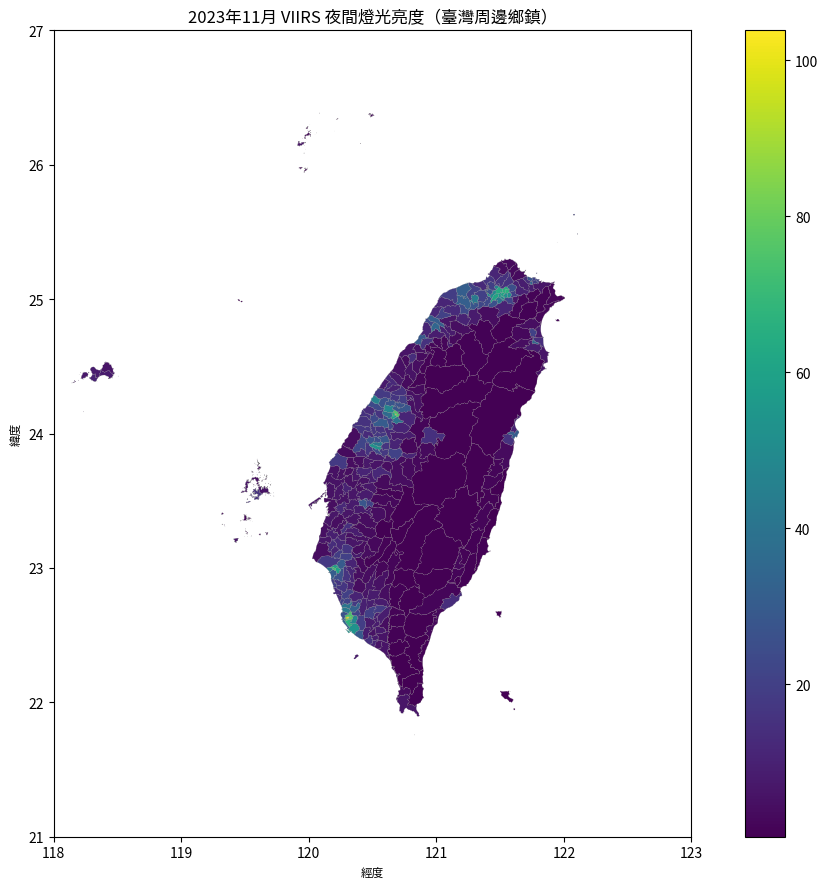

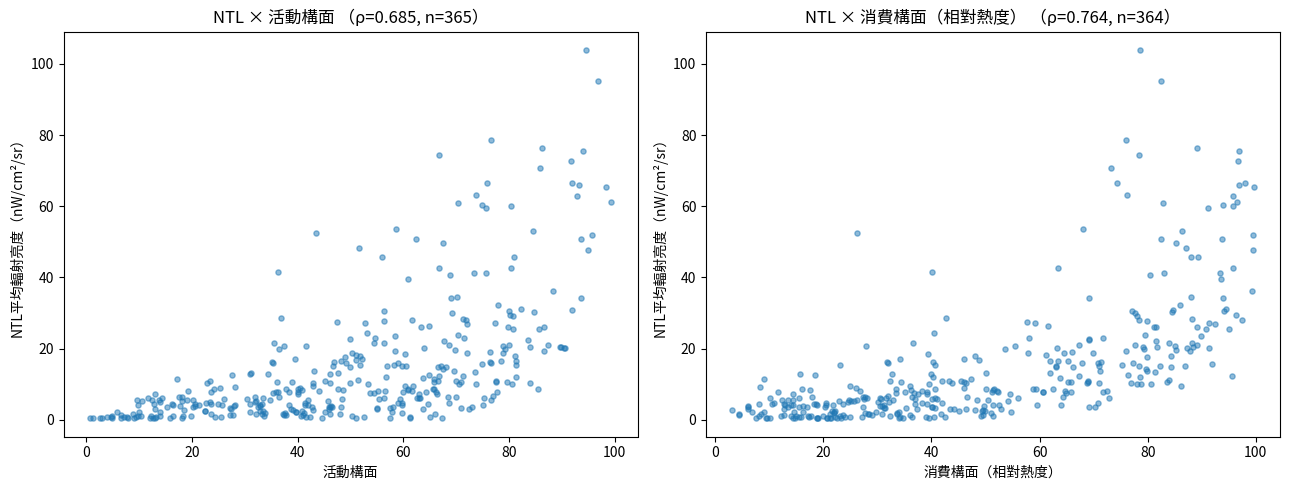

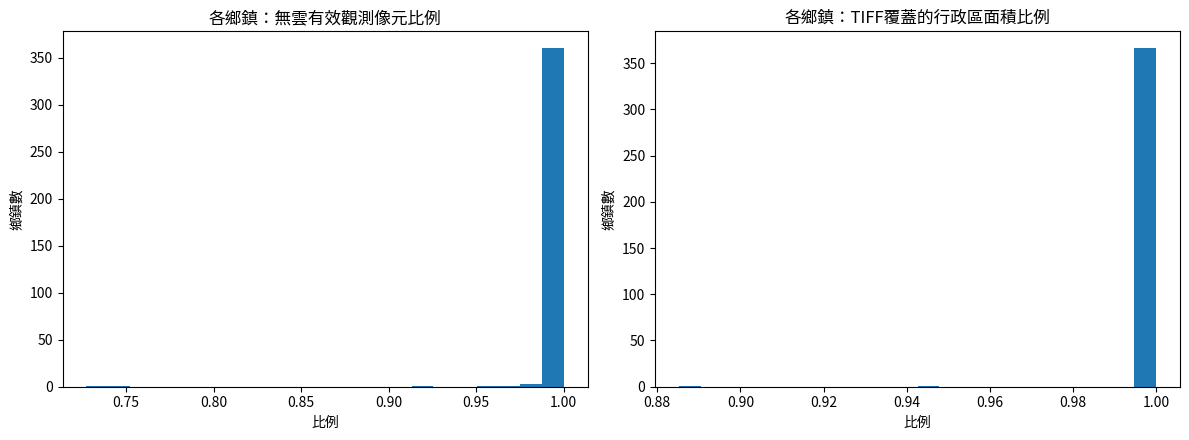

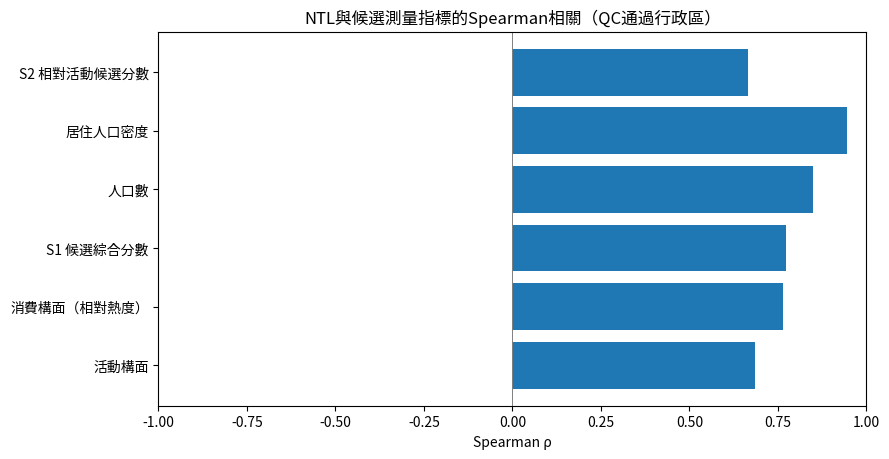

圖檔已輸出：
 - F01_NTL_township_map.png
 - F02_NTL_vs_UVI_dimensions.png
 - F03_NTL_quality_coverage.png
 - F04_NTL_spearman_summary.png


In [11]:
import matplotlib as mpl
# 字型可依Colab環境使用 Noto CJK；若顯示缺字，下方安裝一個通用可用的中文系統字體
import subprocess

font_path=Path('/usr/share/fonts/opentype/noto/NotoSansCJK-Regular.ttc')
if not font_path.exists():
    try: subprocess.run(['apt-get','-qq','install','-y','fonts-noto-cjk'],stdout=subprocess.DEVNULL,stderr=subprocess.DEVNULL,timeout=90,check=False)
    except subprocess.TimeoutExpired: print('中文顯示字型安裝逾時；圖表仍會照常輸出。')
mpl.font_manager.fontManager.addfont('/usr/share/fonts/opentype/noto/NotoSansCJK-Regular.ttc') if Path('/usr/share/fonts/opentype/noto/NotoSansCJK-Regular.ttc').exists() else None
mpl.rcParams['font.sans-serif']=['Noto Sans CJK JP','DejaVu Sans']
mpl.rcParams['axes.unicode_minus']=False

geo_merged=boundary[['town_code','geometry']].merge(merged,on='town_code',how='left',validate='one_to_one')
geo_merged=gpd.GeoDataFrame(geo_merged,geometry='geometry',crs=boundary.crs).to_crs('EPSG:4326')

fig,ax=plt.subplots(figsize=(11,9))
geo_merged.plot(column='ntl_mean_cf1',ax=ax,legend=True,linewidth=.12,edgecolor='grey',missing_kwds={'color':'lightgrey','label':'無有效觀測'})
ax.set_xlim(118,123);ax.set_ylim(21,27)
ax.set_title('2023年11月 VIIRS 夜間燈光亮度（臺灣周邊鄉鎮）')
ax.set_xlabel('經度');ax.set_ylabel('緯度')
fig.tight_layout();fig.savefig(OUT/'F01_NTL_township_map.png',dpi=180,bbox_inches='tight');plt.show()

fig,axes=plt.subplots(1,2,figsize=(13,5))
for ax,(x,title) in zip(axes,[(COMPARE['活動構面'],'活動構面'),(COMPARE['消費構面（相對熱度）'],'消費構面（相對熱度）')]):
    a=merged.loc[merged.ntl_qc_flag=='OK',[x,'ntl_mean_cf1']].dropna()
    ax.scatter(a[x],a['ntl_mean_cf1'],alpha=.5,s=14)
    rho=spearmanr(a[x],a['ntl_mean_cf1']).statistic if len(a)>3 else np.nan
    ax.set_title(f'NTL × {title} （ρ={rho:.3f}, n={len(a)}）')
    ax.set_xlabel(title);ax.set_ylabel('NTL平均輻射亮度（nW/cm²/sr）')
fig.tight_layout();fig.savefig(OUT/'F02_NTL_vs_UVI_dimensions.png',dpi=180);plt.show()

fig,axes=plt.subplots(1,2,figsize=(12,4.5))
axes[0].hist(merged['ntl_cf_valid_ratio'].dropna(),bins=22)
axes[0].set_title('各鄉鎮：無雲有效觀測像元比例'); axes[0].set_xlabel('比例');axes[0].set_ylabel('鄉鎮數')
axes[1].hist(merged['ntl_raster_coverage_ratio'].dropna(),bins=22)
axes[1].set_title('各鄉鎮：TIFF覆蓋的行政區面積比例');axes[1].set_xlabel('比例');axes[1].set_ylabel('鄉鎮數')
fig.tight_layout();fig.savefig(OUT/'F03_NTL_quality_coverage.png',dpi=180);plt.show()

summary=assoc.loc[assoc.analysis_scope=='QC_OK'].copy()
fig,ax=plt.subplots(figsize=(9,4.7))
ax.barh(summary['comparison'],summary['spearman_rho'])
ax.axvline(0,color='grey',lw=.7);ax.set_xlim(-1,1)
ax.set_title('NTL與候選測量指標的Spearman相關（QC通過行政區）');ax.set_xlabel('Spearman ρ')
fig.tight_layout();fig.savefig(OUT/'F04_NTL_spearman_summary.png',dpi=180,bbox_inches='tight');plt.show()
print('圖檔已輸出：',*(p.name for p in sorted(OUT.glob('F0*_NTL_*.png'))),sep='\n - ')

## 步驟 11（選用）｜探索性「增益」比較：加入 NTL 後預測候選 S1 是否改善

這個分析是 **探索性代理預測**，並不是完整 UVI 效度驗證。因為 S1 是用人流和消費構成的候選指標，用 NTL 去預測 S1，即使有增益，也不能說「夜光驗證了真實城市活力」。

這裡用 **以縣市為分組的5折交叉驗證**，比較人口／人口密度基準與額外加上NTL的 Ridge 模型，回報平均R²與MAE；不洩漏同縣市資料進不同的訓練與測試折。

In [12]:
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.metrics import r2_score,mean_absolute_error
usable=merged.loc[(merged.ntl_qc_flag=='OK') & merged.ntl_mean_cf1.notna()].copy()
usable['log_pop']=np.log1p(usable.population_total)
usable['log_density']=np.log1p(usable.population_density_2023)
usable['log_ntl']=np.log1p(usable.ntl_mean_cf1.clip(lower=0))
cols=['log_pop','log_density','log_ntl','S1_equal_domains_median_business_tax','county_name']
usable=usable[cols].replace([np.inf,-np.inf],np.nan).dropna()
if len(usable)<30 or usable.county_name.nunique()<5:
    print('可用鄉鎮或縣市數量不足，略過探索性模型。')
else:
    cv=GroupKFold(n_splits=5)
    y=usable['S1_equal_domains_median_business_tax'].to_numpy()
    groups=usable['county_name']
    modelrows=[]
    for label,feature_names in [('人口+密度',['log_pop','log_density']),('人口+密度+NTL',['log_pop','log_density','log_ntl'])]:
        X=usable[feature_names].to_numpy()
        for k,(train,test) in enumerate(cv.split(X,y,groups),1):
            mdl=make_pipeline(StandardScaler(),Ridge(alpha=1.0))
            mdl.fit(X[train],y[train])
            pred=mdl.predict(X[test])
            modelrows.append({'model':label,'fold':k,'n_test':len(test),'r2':r2_score(y[test],pred),'mae':mean_absolute_error(y[test],pred)})
    cv_results=pd.DataFrame(modelrows)
    cv_results.to_csv(OUT/'NTL_202311_exploratory_groupCV_Ridge.csv',index=False,encoding='utf-8-sig')
    display(cv_results.groupby('model')[['r2','mae']].mean().round(4))
    print('注意：這是預測候選 S1 的探索性代理模型，不是獨立效度／政策因果驗證。')

,r2,mae
model,,
人口+密度,0.6077,11.8795
人口+密度+NTL,0.6156,11.7830


注意：這是預測候選 S1 的探索性代理模型，不是獨立效度／政策因果驗證。


## 步驟 12｜自動輸出研究方法與品質報告，打包下載

本步會把分析產出留在 Drive `UVI_NTL/output/`，並整理成一個 ZIP。

請把這個 ZIP 丟回 ChatGPT，我就能**根據真實跑出的新數據**更新研究報告、NTL研究結果、圖表與教授報告內容。

In [13]:
from datetime import datetime,timezone
out_files=[p for p in OUT.iterdir() if p.is_file()]
qa={
 'study':'Taiwan UVI 2023-11 EOG VIIRS NTL zonal statistics',
 'generated_utc':datetime.now(timezone.utc).isoformat(),
 'radiance_input':str(RAD_CLIP), 'coverage_input':str(CF_CLIP),
 'boundary_source':BOUNDARY_SOURCE,
 'raster_crs':str(RASTER_CRS),
 'n_townships':int(len(merged)),
 'n_valid_townships':int(merged.ntl_mean_cf1.notna().sum()),
 'n_qc_ok':int((merged.ntl_qc_flag=='OK').sum()),
 'quality_gate':{'min_cf_main':MIN_CF_MAIN,'min_cf_sensitivity':MIN_CF_SENSITIVITY,'min_raster_coverage_ratio':0.95,'min_valid_observation_ratio':0.50,'all_touched':ALL_TOUCHED},
 'flag_counts':{str(k):int(v) for k,v in merged.ntl_qc_flag.value_counts().items()},
 'caveats':['NTL=夜間衛星輻射亮度，不是人流或消費實額', 'S1–S6是候選診斷分數，不是最終UVI', '2023年11月NTL與年度消費熱度的時間尺度不相同', '加入NTL預測S1僅為探索性代理預測，非獨立效度驗證']
}
(OUT/'NTL_202311_qc_summary.json').write_text(json.dumps(qa,ensure_ascii=False,indent=2),encoding='utf-8')
lines=[
 '# 2023年11月VIIRS夜間燈光與UVI候選指標比較｜方法與品質紀錄',
 '',
 '## 資料與方法',
 '- 原始產品：Earth Observation Group VIIRS Monthly DNB Composite，2023/11，VCMCFG。',
 '- 夜光亮度：avg_rade9h（nW/cm²/sr）；有效無雲觀測：cf_cvg（觀測次數）。',
 '- 統計單位：2023年鄉鎮市區界線，依8碼TOWNCODE與UVI主表連結。',
 f'- 像元納入條件：cf_cvg≥{MIN_CF_MAIN}；敏感度採≥{MIN_CF_SENSITIVITY}；all_touched={ALL_TOUCHED}。',
 '- 平均亮度：以像元中心屬於該區、且符合品質條件的像元為樣本；經緯度格網採cos(緯度)近似面積加權。',
 '- 品質旗標：行政區實際被裁切圖覆蓋比例低於95%；有效像元比例低於50%；或像元少於5（優先順序判定）。',
 '- 與活動、消費及人口進行Spearman等級相關；對平均／中位／P90另作控制人口秩後偏Spearman。',
 '- 偏相關的傳統p值未調整空間相依，僅供探索；異常鄉鎮依NTL與構面相對百分位差篩選。',
 '- 可選做以縣市分組的5折Ridge代理預測比較。',
 '',
 '## 運算摘要',
 f'- 鄉鎮總數：{len(merged)}',
 f'- 有有效NTL平均亮度的鄉鎮：{qa["n_valid_townships"]}',
 f'- 符合預設QC門檻的鄉鎮：{qa["n_qc_ok"]}',
 f'- 各品質旗標：{qa["flag_counts"]}',
 '',
 '## 研究詮釋邊界',
 '本次量測的是夜間衛星輻射亮度與既有UVI候選構面的統計關聯，不能直接推論夜間行人數、消費實額、政策因果效果，亦不自動將NTL加入UVI。',
 '地圖若僅展示118–123E的臺灣周邊，完整研究結果仍需檢查金門、馬祖、澎湖與其他外島品質旗標。',
 '',
 '## 研究表格',
 assoc.to_markdown(index=False,floatfmt='.4f'),
 '',
 '## 控制人口後偏相關',
 partial_results.to_markdown(index=False,floatfmt='.4f'),
 '',
 '## 相對落差候選地區（前30筆）',
 anomalies.head(30).to_markdown(index=False,floatfmt='.3f'),
 '',
 '## 來源',
 'EOG：https://eogdata.mines.edu/products/vnl/',
 '內政部國土測繪中心：https://maps.nlsc.gov.tw/pro/download.jsp',
 'UVI Stage 1 Academic Audit v0.1 (2026-09-25)，town_code精確對接。'
]
(OUT/'NTL_202311_methods_results.md').write_text('\n'.join(lines),encoding='utf-8')

files_for_zip=[]
for p in sorted(OUT.iterdir()):
    if p.is_file() and (p.name.startswith(('NTL_202311','F01_NTL','F02_NTL','F03_NTL','F04_NTL','UVI_2023_township_scores'))):
        files_for_zip.append(p)
# 裁切 TIFF 小於 150MB 時一起打包，方便回傳 ChatGPT；大型原始地球圖磚不打包
if RAD_CLIP.stat().st_size + CF_CLIP.stat().st_size < 150*1024*1024:
    for p in (RAD_CLIP,CF_CLIP):
        if p not in files_for_zip:files_for_zip.append(p)
else:
    print('裁切 TIFF 合計超過150MB，請保留在 Drive，不放進交接 ZIP。')
zip_path=OUT/'UVI_NTL_202311_研究結果_交回ChatGPT.zip'
with zipfile.ZipFile(zip_path,'w',compression=zipfile.ZIP_DEFLATED,compresslevel=6) as z:
    for p in files_for_zip:z.write(p,arcname=p.name)
print('分析完成。')
print('統計表：',OUT/'NTL_202311_township_zonal_stats.csv')
print('整合表：',OUT/'NTL_202311_UVI_merged.csv')
print('打包檔：',zip_path,'（MB）',round(zip_path.stat().st_size/1e6,2))
print('請將 ZIP 下載後，上傳到 ChatGPT 進行正式研究報告更新。')

分析完成。
統計表： /content/drive/MyDrive/UVI_NTL/output/NTL_202311_township_zonal_stats.csv
整合表： /content/drive/MyDrive/UVI_NTL/output/NTL_202311_UVI_merged.csv
打包檔： /content/drive/MyDrive/UVI_NTL/output/UVI_NTL_202311_研究結果_交回ChatGPT.zip （MB） 4.23
請將 ZIP 下載後，上傳到 ChatGPT 進行正式研究報告更新。


## 步驟 13（可選）｜下載 ZIP 到電腦

如果想直接把結果上傳到 ChatGPT，執行下面這格就會觸發瀏覽器下載；不按也沒關係，輸出已留在 Google Drive 的 `UVI_NTL/output`。

In [14]:
from google.colab import files
files.download(str(zip_path))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>